<a href="https://colab.research.google.com/github/khkim82004-star/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_7%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 오픈소스 기반 데이터 분석 7강 - 데이터 전처리 2

### 7-1 데이터 결측치 찾기

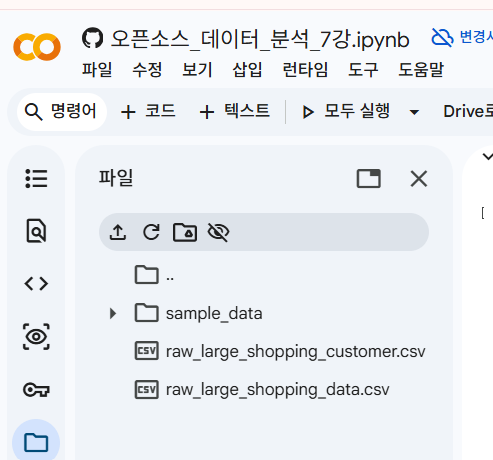

In [4]:
import pandas as pd
import numpy as np

data = {'이름': ['김철수', '이영희', '박민수', '최지훈', '정소희'],
        '나이': [25, 30, np.nan, 22, 35],
        '도시': ['서울', None, '인천', '서울', '대전'],
        '점수': [90, 85, np.nan, 80, 92]}

df = pd.DataFrame(data)

##--- 결측치 여부 확인
df.isnull()
df.isna() #동일한 결과 출력


,이름,나이,도시,점수
0,False,False,False,False
1,False,False,True,False
2,False,True,False,True
3,False,False,False,False
4,False,False,False,False


In [5]:
## 열별, 행별 결측치 개수 확인
df.isnull().sum() #기본적으로는 몇 개의 행인지 더함

,0
이름,0
나이,1
도시,1
점수,1


In [6]:
df.isnull().sum(axis=1) #축의 방향을 바꿈(행단위-가로방향으로 묶음)

,0
0,0
1,1
2,2
3,0
4,0


In [7]:
## 특정 열, 행 결측치 확인
df[df.isnull().any(axis=1)] #any함수:한개이상이면 출력


,이름,나이,도시,점수
1,이영희,30.0,None,85.0
2,박민수,NaN,인천,NaN


In [8]:
df[df['나이'].isnull()] #나이가 null인 것만 출력

,이름,나이,도시,점수
2,박민수,NaN,인천,NaN


In [9]:
## 결측치가 아닌 항목 확인
df.notnull()

,이름,나이,도시,점수
0,True,True,True,True
1,True,True,False,True
2,True,False,True,False
3,True,True,True,True
4,True,True,True,True


In [10]:
## 결측치 비율: 전체 데이터 항목 중 null 값이 몇 개가 있는가?
df.isnull().sum().sum() / (df.shape[0] * df.shape[1]) * 100

np.float64(15.0)

### 7-2 데이터 시각화를 이용한 결측치 찾기

In [11]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [12]:
import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

세션 다시 시작

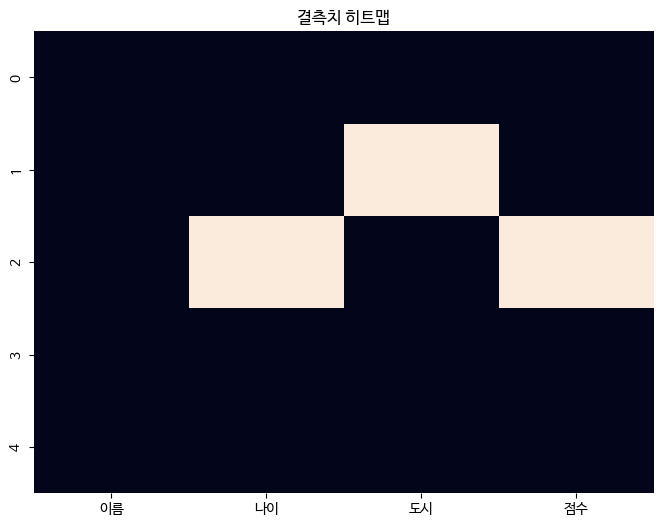

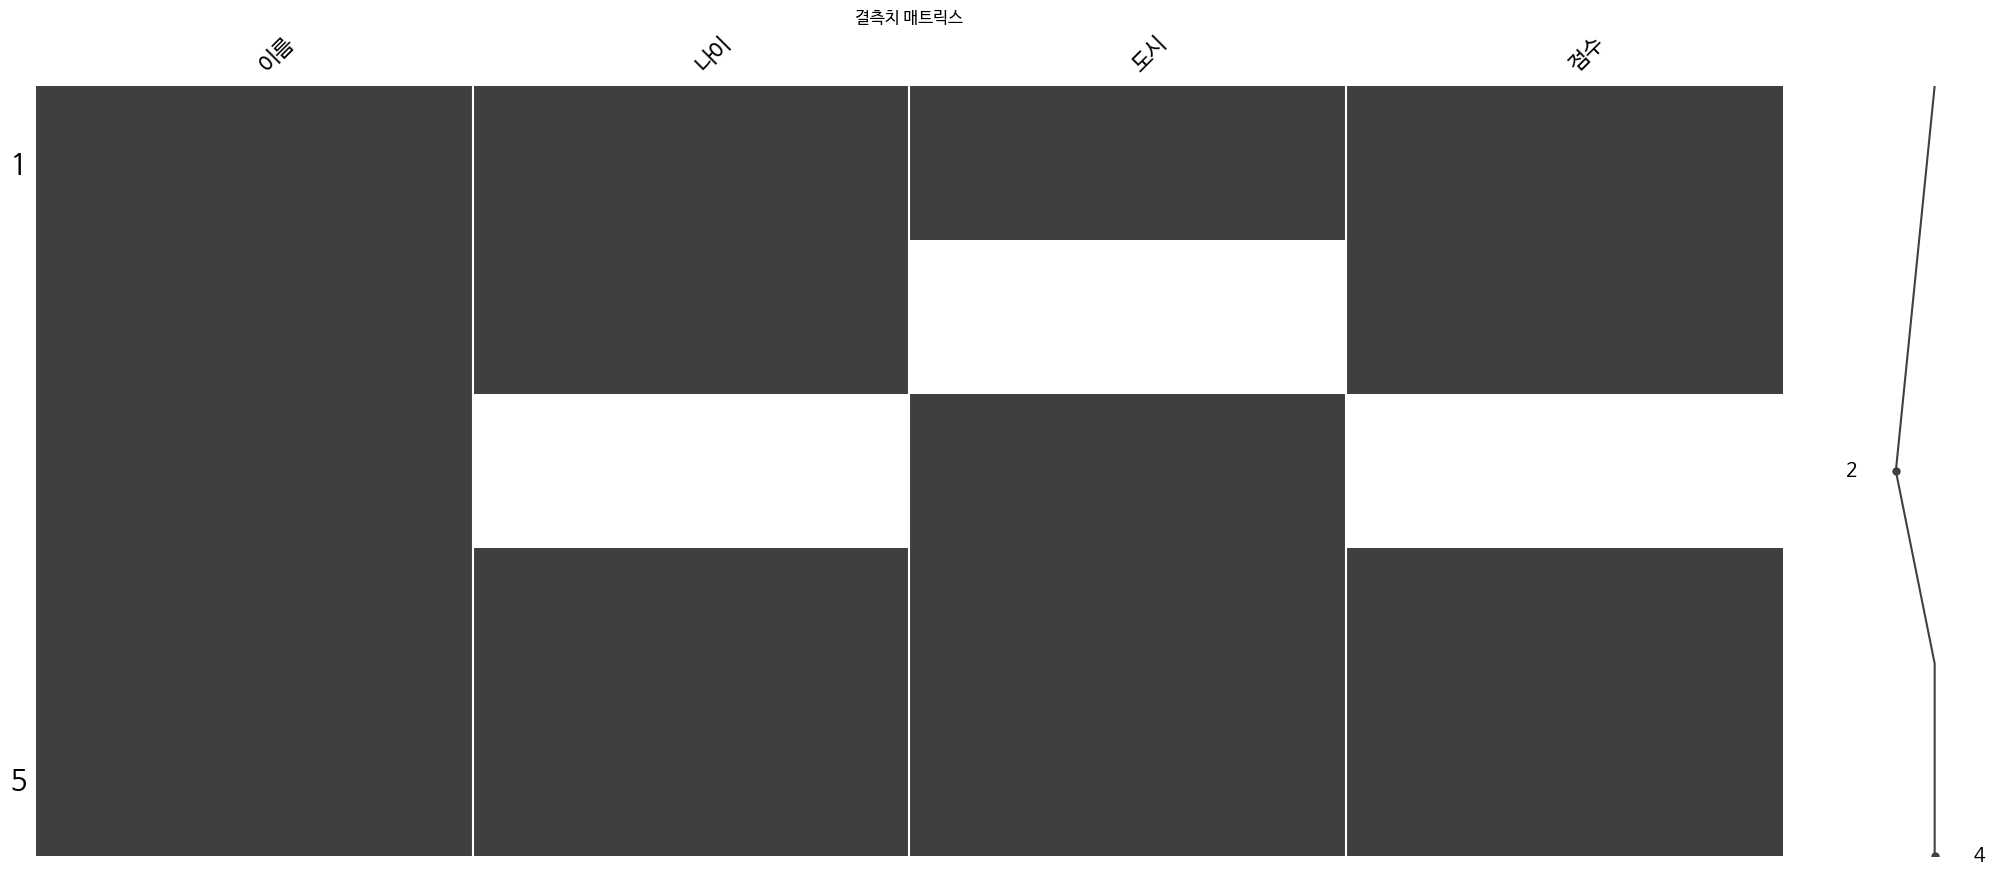

In [13]:
import numpy as np
import pandas as pd

###--- 시각화 라이브러리 임포트
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

data = {'이름': ['김철수', '이영희', '박민수', '최지훈', '정소희'],
        '나이': [25, 30, np.nan, 22, 35],
        '도시': ['서울', None, '인천', '서울', '대전'],
        '점수': [90, 85, np.nan, 80, 92]}
df = pd.DataFrame(data)

### 결측치 히트맵
plt.figure(figsize=(8, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("결측치 히트맵")
plt.show()

### 결측치 매트릭스
msno.matrix(df)
plt.title("결측치 매트릭스")
plt.show()

### 7-3 사분위 범위를 통한 이상치 찾기

In [14]:
import pandas as pd
import numpy as np

점수_데이터 = [72, 68, 75, 282, 64, 31, 78, 69, 88, 92, 22, 84, 61, -90, 130, 66]
학번_데이터 = list(range(1001, 1001 + len(점수_데이터)))

df = pd.DataFrame({
    '학번': 학번_데이터,
    '점수': 점수_데이터
})

###--- 사분위 범위 경계값 계산
q1 = df['점수'].quantile(0.25)
q3 = df['점수'].quantile(0.75)
iqr = q3 - q1
하한값 = q1 - 1.5 * iqr
상한값 = q3 + 1.5 * iqr

###--- IQR 통계량 출력
print(q1)
print(q3)
print(iqr)
print(하한값)
print(상한값)


63.25
85.0
21.75
30.625
117.625


### 7-4 Z-점수를 통한 이상치 찾기

In [15]:
import pandas as pd
import numpy as np

점수_데이터 = [72, 68, 75, 282, 64, 31, 78, 69, 88, 92, 22, 84, 61, -90, 130, 66]
학번_데이터 = list(range(1001, 1001 + len(점수_데이터)))

df = pd.DataFrame({
    '학번': 학번_데이터,
    '점수': 점수_데이터
})

###--- Z-점수 계산
점수_평균 = df['점수'].mean()
점수_표준편차 = df['점수'].std()
df['점수_Z'] = (df['점수'] - 점수_평균) /점수_표준편차
df

,학번,점수,점수_Z
0,1001,72,-0.034475
1,1002,68,-0.089635
2,1003,75,0.006895
3,1004,282,2.861411
4,1005,64,-0.144794
5,1006,31,-0.599862
6,1007,78,0.048265
7,1008,69,-0.075845
8,1009,88,0.186164
9,1010,92,0.241324


In [16]:
###--- 임계값 설정 및 이상치 여부 판단
임계값 = 2
df['이상치여부'] = df['점수_Z'].abs() > 임계값
df

,학번,점수,점수_Z,이상치여부
0,1001,72,-0.034475,False
1,1002,68,-0.089635,False
2,1003,75,0.006895,False
3,1004,282,2.861411,True
4,1005,64,-0.144794,False
5,1006,31,-0.599862,False
6,1007,78,0.048265,False
7,1008,69,-0.075845,False
8,1009,88,0.186164,False
9,1010,92,0.241324,False


In [17]:
###--- 이상치 데이터 출력
df[df['이상치여부']]

,학번,점수,점수_Z,이상치여부
3,1004,282,2.861411,True
13,1014,-90,-2.268444,True


In [18]:
###--- 이상치 비율 출력
df['이상치여부'].mean() * 100


np.float64(12.5)

### 7-5 평균값 및 선형보간법을 통한 결측치 처리

In [19]:
import pandas as pd
import numpy as np

file_path = "raw_large_shopping_customer.csv"
df = pd.read_csv(file_path)
print(df.isnull().sum())

ID         0
나이        50
소득        50
지출        50
평균구매횟수    50
dtype: int64


In [20]:
#결측치가 2개 이상인 걸 삭제: dropna함수 사용
df_cleaned = df.dropna(thresh=df.shape[1] - 1)
#4개 이상의 값이 채워져있는 것만 남기고 삭제

### 나이, 소득 평균값으로 대치 및 결과 출력
#나이와 소득만 인덱싱하고, 나이와 소득의 평균값으로 채움, fillna함수 사용
df_cleaned.loc[:, ['나이', '소득']] = df_cleaned[['나이', '소득']].fillna(df_cleaned[['나이','소득']].mean())

### 지출, 평균구매횟수 선형보간법 적용
#지출, 평균구매횟수 인덱싱, interpolate 함수 사용
df_cleaned.loc[:, ['지출','평균구매횟수']] = df_cleaned[['지출', '평균구매횟수']].interpolate(method='linear')

df_cleaned.to_csv("cleaned_large_shopping_customer.csv", index=False, encoding="utf-8-sig")

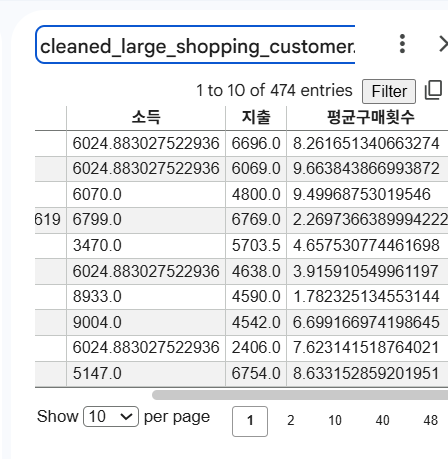

### 7-6 DataFrame 값 변경

In [21]:
import pandas as pd

data = {'age': [25, 30, None, 22, 35],
        'city': ['Seoul', None, 'Incheon', 'Seoul', 'Daejeon'],
        'score': [90, 85, None, 80, 92]}
df = pd.DataFrame(data)

### replace를 이용한 Seoul -> 서울: 영문을 한글로 바꿈
df['city'] = df['city'].replace('Seoul','서울')
print(df)

    age     city  score
0  25.0       서울   90.0
1  30.0     None   85.0
2   NaN  Incheon    NaN
3  22.0       서울   80.0
4  35.0  Daejeon   92.0


In [22]:
### replace를 이용한 None -> 미정, Incheon -> 인천
#여러 개의 값을 바꿈: 딕셔너리 쌍으로 나열함
df['city'] = df['city'].replace({None:'미정', 'Incheon':'인천'})

### map을 이용한 값 변경: 딕셔너리를 넣을 수도 있고 함수를 넣을 수도 있다.
df = pd.DataFrame(data)
city_map = {'Seoul': '서울특별시', None: '미정', 'Incheon':'인천광역시', 'Daejeon':'대전광역시'}
# map 함수는 딕셔너리를 넣을 수도 있고 함수를 넣을 수도 있다.
df['city'] = df['city'].map(city_map)
#람다함수 이용
df['age_str'] = df['age'].map(lambda x: f" {x}살" if pd.notna(x) else '알수없음')

### apply 함수를 이용한 값 변경
#함수 정의
def age_plus_score(row):
    age = row['age'] if pd.notna(row['age']) else 0
    score = row['score'] if pd.notna(row['score']) else 0
    return age + score
#데이터프레임에 적용: axis=1:행단위로 적용
df['age_pluse_score'] = df.apply(age_plus_score, axis =1)

### apply 함수를 이용한 행단위 값 변경
#함수 정의
def age_plus_score(row):
    age = row['age'] if pd.notna(row['age']) else 0
    score = row['score'] if pd.notna(row['score']) else 0
    return age + score
#데이터프레임에 적용
df['age_plus_score'] = df.apply(age_plus_score, axis=1)
print("\napply함수를 이용한 행단위 값 변경:\n", df['age_plus_score'])


apply함수를 이용한 행단위 값 변경:
 0    115.0
1    115.0
2      0.0
3    102.0
4    127.0
Name: age_plus_score, dtype: float64


In [23]:
### loc 인덱스를 이용한 값 변경
df.loc[df['score'] < 90, 'score'] = 90
print("\n점수가 90점 미만인 사람 90점으로 변경:\n",df)


점수가 90점 미만인 사람 90점으로 변경:
     age   city  score age_str  age_pluse_score  age_plus_score
0  25.0  서울특별시   90.0   25.0살            115.0           115.0
1  30.0     미정   90.0   30.0살            115.0           115.0
2   NaN  인천광역시    NaN    알수없음              0.0             0.0
3  22.0  서울특별시   90.0   22.0살            102.0           102.0
4  35.0  대전광역시   92.0   35.0살            127.0           127.0


In [24]:
### where 함수를 이용한 값 변경
df['age_where'] = df['age'].where(df['age']>=30,other=0)
print("\nage가 30이상인 값만 유지하고 나머지를 0으로 변경\n",df['age_where'])


age가 30이상인 값만 유지하고 나머지를 0으로 변경
 0     0.0
1    30.0
2     0.0
3     0.0
4    35.0
Name: age_where, dtype: float64


### 7-7 날짜 데이터 타입 다루기


In [25]:
date_str = ['2025-07-01', '2025-08-01', '2025-09-01']
df_date = pd.DataFrame({'date_str':date_str})

### datetime 타입 변환
df_date['date'] = pd.to_datetime(df_date['date_str'])
df_date

,date_str,date
0,2025-07-01,2025-07-01
1,2025-08-01,2025-08-01
2,2025-09-01,2025-09-01


In [26]:
### 날짜 데이터 분리
print(df_date['date'].dt.year) #연도만 보고 싶을 때
print(df_date['date'].dt.month) #월만
print(df_date['date'].dt.day) #날
print(df_date['date'].dt.day_name()) #요일

0    2025
1    2025
2    2025
Name: date, dtype: int32
0    7
1    8
2    9
Name: date, dtype: int32
0    1
1    1
2    1
Name: date, dtype: int32
0    Tuesday
1     Friday
2     Monday
Name: date, dtype: object


In [27]:
### 날짜 데이터 포멧 변경: strftime-문자열로
df_date['date_formatted'] = df_date['date'].dt.strftime('%Y/%m/%d')
df_date

,date_str,date,date_formatted
0,2025-07-01,2025-07-01,2025/07/01
1,2025-08-01,2025-08-01,2025/08/01
2,2025-09-01,2025-09-01,2025/09/01


## 7-8 실습 시나리오 - 데이터 정제

### [재수행] 6-5 실습 시나리오 - Kaggle을 활용한 데이터 수집 및 측정

Kaggle(https://www.kaggle.com) 회원 가입
Kaggle 접근 토큰 생성(API 키) legacy로 해야 json 파일 다운받을 수 있음

In [28]:
#코랩에 다운받은 json 파일 업로드
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (1).json


{'kaggle (1).json': b'{"username":"conikim","key":"67aee15df08d219c21de21b4f429c6b1"}'}

In [29]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [30]:
!kaggle competitions download -c store-sales-time-series-forecasting #특정 상점에서 물건 판매된 기록

!unzip store-sales-time-series-forecasting.zip

store-sales-time-series-forecasting.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  store-sales-time-series-forecasting.zip
replace holidays_events.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace oil.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace sample_submission.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace stores.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace test.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace train.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace transactions.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n


In [31]:
import pandas as pd

#--- Grocery Sales 데이터 DataFrame 로드
train = pd.read_csv('train.csv') #read_cs는 함수니 소괄호로 감싸야 함.
stores = pd.read_csv('stores.csv')
transactions = pd.read_csv('transactions.csv')
oil = pd.read_csv('oil.csv')
holidays_events = pd.read_csv('holidays_events.csv')

#--- 판매 데이터 살펴보기
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


In [32]:
#train 데이터 프레임이 잘 생성되었는지 확인
train

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.000,0
1,1,2013-01-01,1,BABY CARE,0.000,0
2,2,2013-01-01,1,BEAUTY,0.000,0
3,3,2013-01-01,1,BEVERAGES,0.000,0
4,4,2013-01-01,1,BOOKS,0.000,0
...,...,...,...,...,...,...
3000883,3000883,2017-08-15,9,POULTRY,438.133,0
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8


### 데이터 분포 시각화

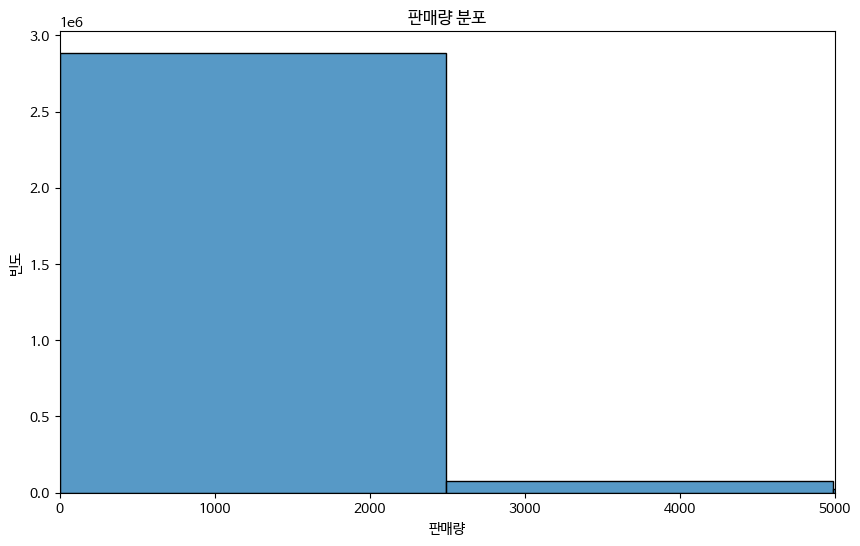

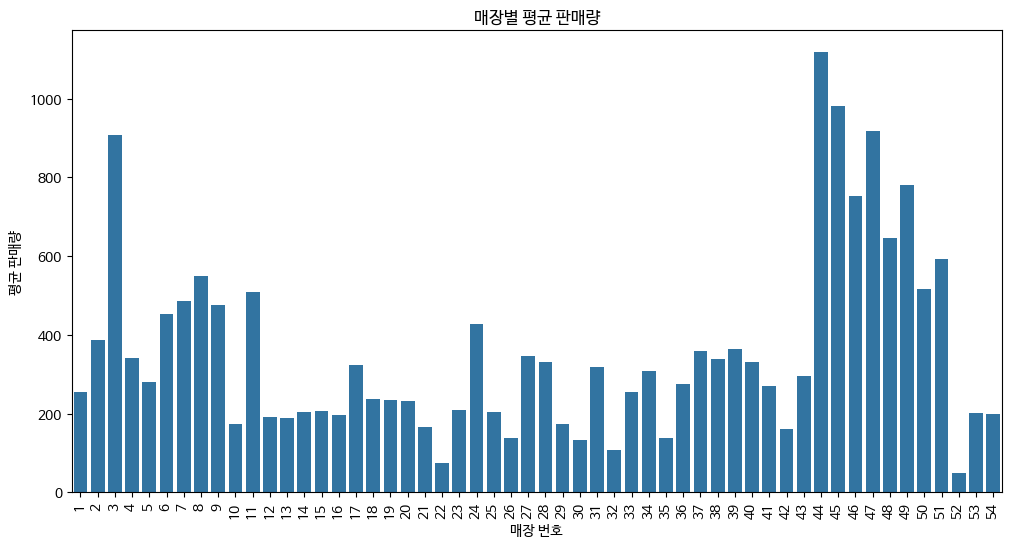

In [33]:
plt.figure(figsize=(10, 6))
sns.histplot(train['sales'], bins=50)
plt.title("판매량 분포")
plt.xlabel("판매량")
plt.ylabel("빈도")
plt.xlim(0, 5000)
plt.show()

store_sales = train.groupby('store_nbr')['sales'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(x='store_nbr', y='sales', data=store_sales)
plt.title("매장별 평균 판매량")
plt.xlabel("매장 번호")
plt.ylabel("평균 판매량")
plt.xticks(rotation=90)
plt.show()

### 결측치 처리
이전 강의 csv 파일 업로드 해야함

In [34]:
## 판매, 매장, 거래, 원유, 휴일이벤트 데이터 결측치 확인
print(train.isnull().sum())
print(stores.isnull().sum())
print(transactions.isnull().sum())
print(oil.isnull().sum())
print(holidays_events.isnull().sum())

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64
date            0
store_nbr       0
transactions    0
dtype: int64
date           0
dcoilwtico    43
dtype: int64
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64


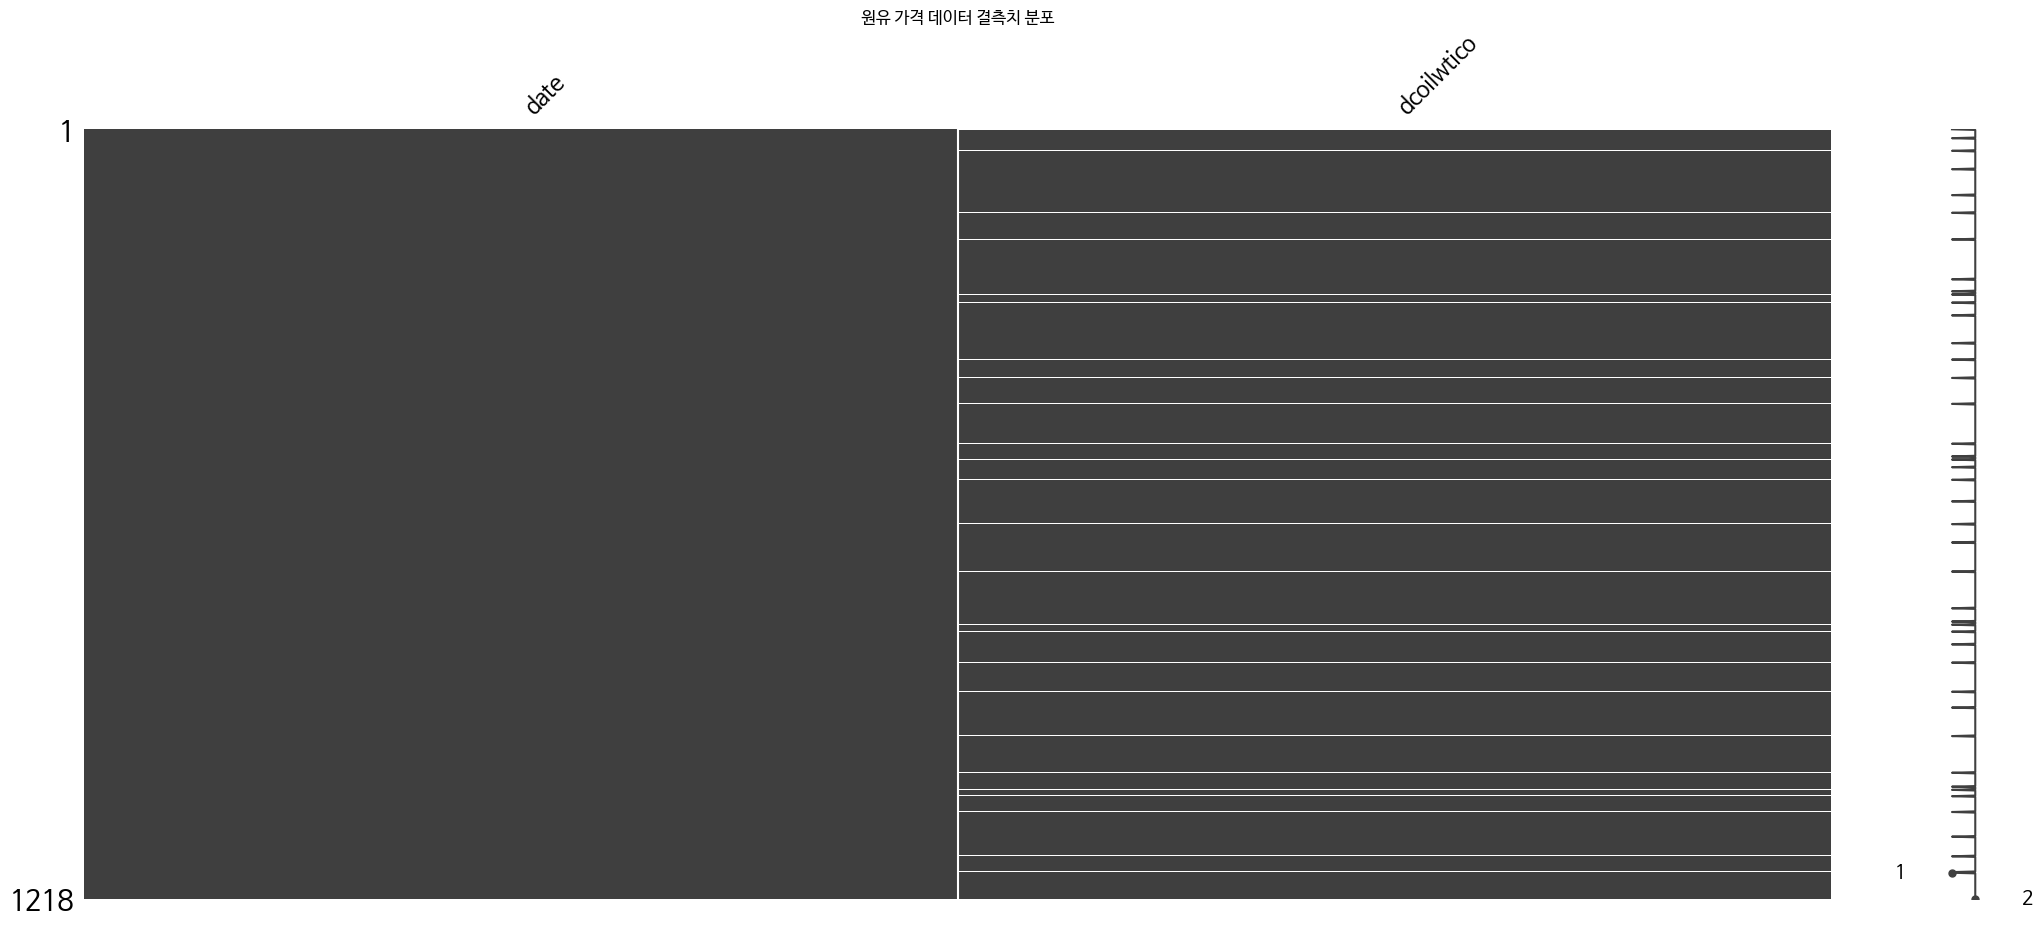

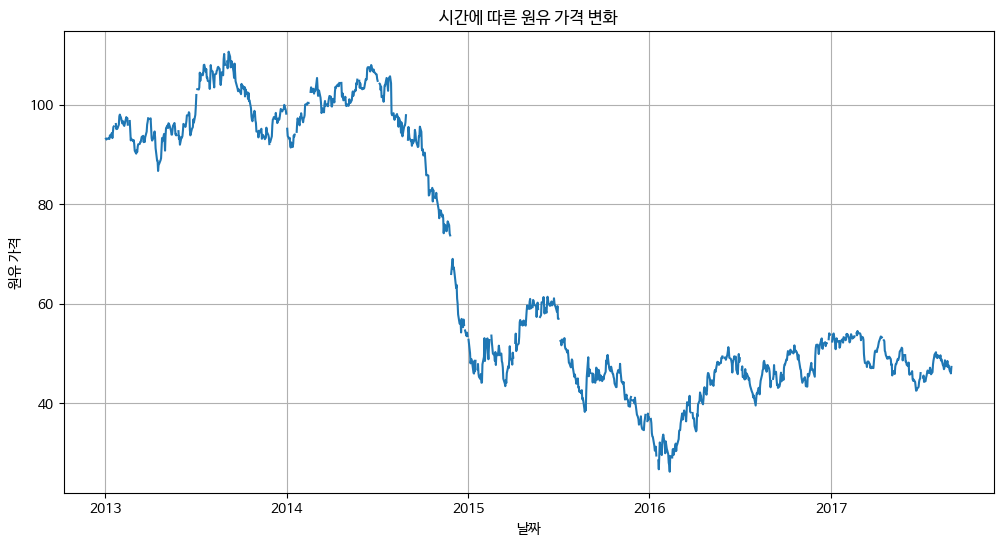

In [35]:
#결측치 분포를 확인하기 위해 시각화함.

import missingno as msno

msno.matrix(oil)
plt.title("원유 가격 데이터 결측치 분포")
plt.show()

oil['date'] = pd.to_datetime(oil['date'])
plt.figure(figsize=(12, 6))
plt.plot(oil['date'], oil['dcoilwtico'])
plt.title("시간에 따른 원유 가격 변화")
plt.xlabel("날짜")
plt.ylabel("원유 가격")
plt.grid(True)
plt.show()

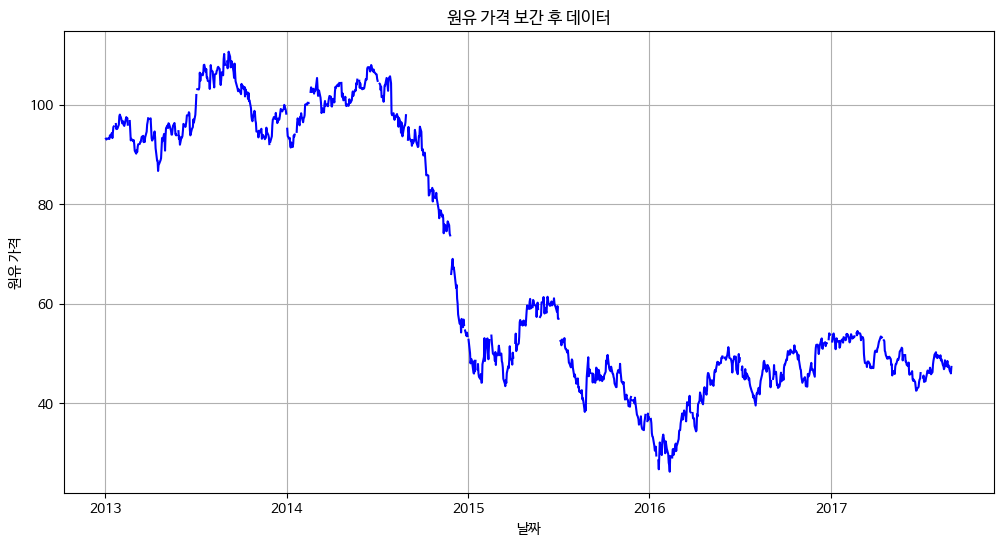

In [36]:
oil_cleaned = oil.copy()

###--- 선형 보간법 적용한 원유 가격 데이터
oil_cleaned['docilwtico'] = oil_cleaned['dcoilwtico'].interpolate(method='linear')
# 보간법을 사용해서 처리

plt.figure(figsize=(12, 6))
plt.plot(oil_cleaned['date'], oil_cleaned['dcoilwtico'], 'b-')
plt.title("원유 가격 보간 후 데이터")
plt.xlabel("날짜")
plt.ylabel("원유 가격")
plt.grid(True)
plt.show()

### 이상치 처리

이상치 개수: 200,274건
전체 대비 비율: 6.67%


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


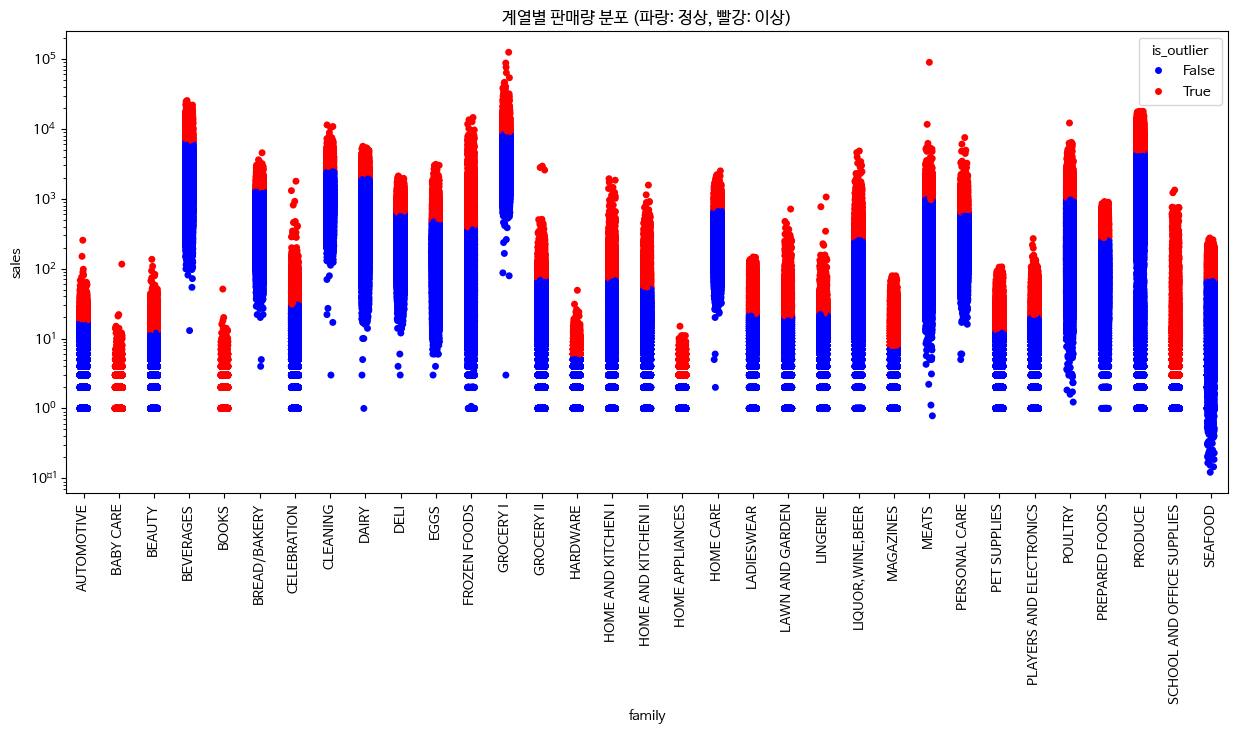

In [37]:
###--- 제품 계열별 판매 데이터 IQR 계산
family_bounds = train.groupby('family')['sales'].apply(
    lambda x: x.quantile(0.75) + 1.5 * (x.quantile(0.75) - x.quantile(0.25))
)

###--- 상한값 초과 판매량 이상치 분류
train_enhanced = train.copy()
train_enhanced['upper_bound'] = train_enhanced['family'].map(family_bounds)
train_enhanced['is_outlier'] = train_enhanced['sales'] > train_enhanced['upper_bound']

total_outliers = train_enhanced['is_outlier'].sum()
total_ratio = train_enhanced['is_outlier'].mean()

#---

print(f"이상치 개수: {total_outliers:,}건")
print(f"전체 대비 비율: {total_ratio:.2%}")

plt.figure(figsize=(15,6))
sns.stripplot(x='family', y='sales', hue=train_enhanced['is_outlier'],
              data=train_enhanced, palette={False:'blue', True:'red'})
plt.xticks(rotation=90)
plt.yscale('log')
plt.title('계열별 판매량 분포 (파랑: 정상, 빨강: 이상)')
plt.show()

In [38]:
### 판매량이 상한값 초과 시, 판매량으로 상한값으로 대체
train_cleaned  = train.copy()
#이상치인 걸 선택하고, sales 컬럼에 대해 새 값을 채움
train_cleaned.loc[train_enhanced['is_outlier'], 'sales'] = \
    train_enhanced.loc[train_enhanced['is_outlier'], 'upper_bound']
#train_enhanced: upper_bound 값으로 대치함

changed_count = (train['sales'] != train_cleaned ['sales']).sum()
print(f"대체된 데이터 수: {changed_count}건")

대체된 데이터 수: 200274건


### 날짜 데이터 처리

In [39]:
###--- 판매, 거래, 휴일 이벤트, 원율 데이터 내 date 컬럼 데이터 datetime 데이터 타입으로 변경
train_cleaned['date'] = pd.to_datetime(train_cleaned['date'])
transactions['date'] = pd.to_datetime(transactions['date'])
holidays_events['date'] = pd.to_datetime(holidays_events['date'])
oil_cleaned['date'] = pd.to_datetime(oil_cleaned['date'])
###---

train_cleaned['year'] = train_cleaned['date'].dt.year
train_cleaned['month'] = train_cleaned['date'].dt.month
train_cleaned['day'] = train_cleaned['date'].dt.day
train_cleaned['dayofweek'] = train_cleaned['date'].dt.dayofweek

###--- 주말, 월초, 월말 여부 추철
train_cleaned['weekend'] = train_cleaned['dayofweek'].apply(lambda x:1 if x >= 5 else 0)
train_cleaned['is_month_start'] = train_cleaned['date'].dt.is_month_start
train_cleaned['is_month_end'] = train_cleaned['date'].dt.is_month_end

print("날짜 특성 추출 결과:")
print(train_cleaned[['date', 'year', 'month', 'day', 'dayofweek', 'weekend', 'is_month_start', 'is_month_end']].head())

날짜 특성 추출 결과:
        date  year  month  day  dayofweek  weekend  is_month_start  \
0 2013-01-01  2013      1    1          1        0            True   
1 2013-01-01  2013      1    1          1        0            True   
2 2013-01-01  2013      1    1          1        0            True   
3 2013-01-01  2013      1    1          1        0            True   
4 2013-01-01  2013      1    1          1        0            True   

   is_month_end  
0         False  
1         False  
2         False  
3         False  
4         False  


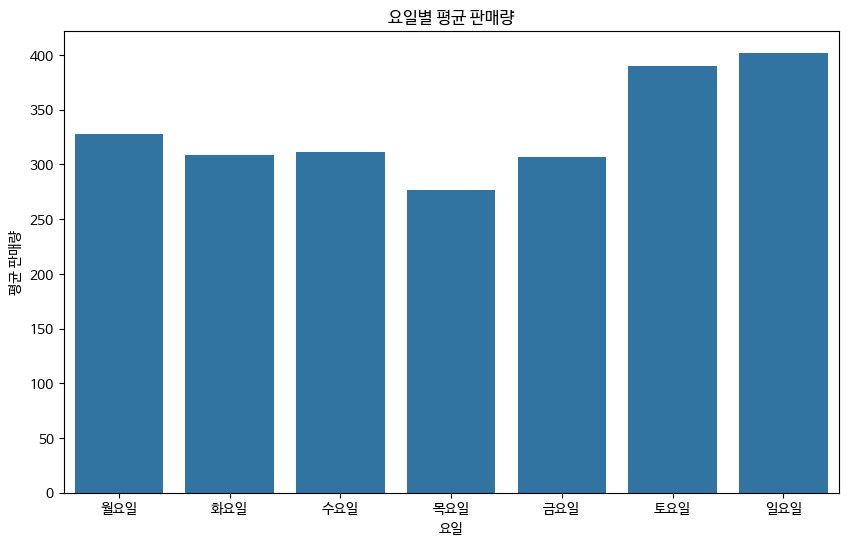

In [40]:
##--- 요일별 평균 판매량을 계산
day_sales = train_cleaned.groupby('dayofweek')['sales'].mean().reset_index()

## 요일 출력값 변경
day_sales['day_name'] = day_sales['dayofweek'].map({
    0: '월요일', 1: '화요일', 2: '수요일', 3: '목요일',
    4: '금요일', 5: '토요일', 6: '일요일'
})

plt.figure(figsize=(10, 6))
sns.barplot(x='day_name', y='sales', data=day_sales)
plt.title("요일별 평균 판매량")
plt.xlabel("요일")
plt.ylabel("평균 판매량")
plt.show()

### 데이터 통합

In [46]:
##--- 판매, 거래 데이터 통합
## merge 사용:두 개의 데이터프레임 합침- 일종의 join (단순히 합치는 게 아)
train_with_trans = pd.merge(
    train_cleaned, transactions,
    on=['date', 'store_nbr'],
    how='left'
)

## 매장 데이터 통합
train_with_store = pd.merge(
    train_with_trans, stores,
    on=['store_nbr'],
    how='left'
)

## 원유 데이터 통합
train_final = pd.merge(
    train_with_store, oil_cleaned,
    on='date', #일자별로 합침
    how='left'
)

print("최종 데이터셋 정보:")
print(f"행 개수: {train_final.shape[0]}, 열 개수: {train_final.shape[1]}")
print(train_final.columns.tolist())
print(train_final.head())

최종 데이터셋 정보:
행 개수: 3000888, 열 개수: 20
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'year', 'month', 'day', 'dayofweek', 'weekend', 'is_month_start', 'is_month_end', 'transactions', 'city', 'state', 'type', 'cluster', 'dcoilwtico', 'docilwtico']
   id       date  store_nbr      family  sales  onpromotion  year  month  day  \
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0  2013      1    1   
1   1 2013-01-01          1   BABY CARE    0.0            0  2013      1    1   
2   2 2013-01-01          1      BEAUTY    0.0            0  2013      1    1   
3   3 2013-01-01          1   BEVERAGES    0.0            0  2013      1    1   
4   4 2013-01-01          1       BOOKS    0.0            0  2013      1    1   

   dayofweek  weekend  is_month_start  is_month_end  transactions   city  \
0          1        0            True         False           NaN  Quito   
1          1        0            True         False           NaN  Quito   
2          1        0    